# Journey Selection & Journey Design Experiment Notebook

This notebook implements the two experimental stages owned by Vandan from Slide 5, Slide 8, Slide 9, and Slide 13 of **Behaviorally Grounded Synthetic Personas - Process Design.pptx**:

1. **Stage 1 — Journey Selection (`SELECTION_METHOD`)**:
   - `"provisional_4"`: Original 6-to-4 cluster fold picking the centroid-nearest video (`etPDgRjrnJ8`, `TXiOSZdaLJ8`, `1olbQVO_C-8`, `v9gjg7TDlTA`).
   - `"cluster_k4"`: Direct `K = 4` clustering on centered sentiment shape + 6 discrete emotions (`happy`, `sad`, `anger`, `surprise`, `disgust`, `fear`).
   - `"cluster_high_var"`: Picks recordings within each of the 4 clusters that have high emotional swing and multi-emotion presence instead of flat mean curves.
   - `"random_high_var"`: Seeded random sample of high-variability recordings across the dataset with distinct emotional shifts.

2. **Stage 2 — Journey Design (`GRANULARITY`, `REPRESENTATION`, `STOCHASTICITY`, `PLACEMENT`, `PROMPT_MODE`)**:
   - `GRANULARITY`: `"sentiment_only"` (`-3` to `+3`) vs. `"emotion_breakdown"` (`sentiment` + 6 discrete emotions `0` to `3`).
   - `REPRESENTATION`: `"verbal"` (natural-language behavioral & sarcastic/guarded tone cues) vs. `"quant"` (numerical scores/vectors + behavioral translation).
   - `STOCHASTICITY`: `"fixed"` (deterministic values like `+1.5`) vs. `"range_or_alpha"` (interval ranges `[-1.0, +1.5]` using Adolfo's `alpha` residual spread).
   - `PLACEMENT`: `"system_whole_journey"` (Persona + entire 5-turn emotional cycle in the system prompt, questions separate) vs. `"per_question_stage"` (Persona in system prompt, per-turn stage cue injected with each question).
   - `PROMPT_MODE`: `"single_call"` (1 LLM call per turn with multi-turn memory) vs. `"two_step_chain"` (Step A substantive answer from persona + memory -> Step B emotional modulation to prevent context squeezing).


## 1. Setup & Data Paths


In [1]:
try:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Mounted at /content/drive
Running in Colab: True


In [2]:
import json
import os
import sys
import time
import urllib.error
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Allow importing from local repo `src/` when running locally
for candidate_src in [Path("src"), Path("../src")]:
    if candidate_src.exists() and str(candidate_src.resolve()) not in sys.path:
        sys.path.insert(0, str(candidate_src.resolve()))

DRIVE_ROOTS = [
    "/content/drive/MyDrive/Northwestern x Accenture",
    "/content/drive/My Drive/Northwestern x Accenture",
] if IN_COLAB else []
LOCAL_ROOTS = [".", "./data", "..", "../data", "/tmp/nxa-oct21"]

def first_existing(relative_paths):
    for root in DRIVE_ROOTS + LOCAL_ROOTS:
        for rel in relative_paths:
            p = os.path.join(root, rel)
            if os.path.exists(p):
                return p
    return None

TRANSCRIPT_CSV = first_existing([
    "Dataset/CMU-MOSEI/segment_transcripts_with_labels.csv",
    "CMU-MOSEI/segment_transcripts_with_labels.csv",
    "segment_transcripts_with_labels.csv",
])
ASSIGN_CSV = first_existing([
    "Dataset/CMU-MOSEI/clustering_outputs/cluster_assignments.csv",
    "CMU-MOSEI/clustering_outputs/cluster_assignments.csv",
    "clustering_outputs/cluster_assignments.csv",
])
PERSONA_CSV = first_existing([
    "Dataset/Nvidia_Nemotron-Personas-USA-sample-30.csv",
    "Nvidia_Nemotron-Personas-USA-sample-30.csv",
])
QUESTIONS_TXT = first_existing([
    "Dataset/Questions/Interview questions.txt",
    "Dataset/CMU-MOSEI/questions/Interview questions.txt",
])

assert TRANSCRIPT_CSV and PERSONA_CSV, "Missing CMU-MOSEI transcript CSV or NVIDIA persona sample CSV."
OUTPUT_DIR = (
    os.path.join(os.path.dirname(TRANSCRIPT_CSV), "journey_design_outputs")
    if IN_COLAB
    else "./journey_design_outputs"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Transcripts :", TRANSCRIPT_CSV)
print("Assignments :", ASSIGN_CSV)
print("Personas    :", PERSONA_CSV)
print("Questions   :", QUESTIONS_TXT or "(using default 5 Subscription Manager questions)")
print("Outputs     :", OUTPUT_DIR)

Transcripts : /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/segment_transcripts_with_labels.csv
Assignments : /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/clustering_outputs/cluster_assignments.csv
Personas    : /content/drive/MyDrive/Northwestern x Accenture/Dataset/Nvidia_Nemotron-Personas-USA-sample-30.csv
Questions   : /content/drive/MyDrive/Northwestern x Accenture/Dataset/Questions/Interview questions.txt
Outputs     : /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/journey_design_outputs


## 2. Journey Selection & Journey Design Engine


In [3]:
"""Journey Selection and Journey Design modules for Behaviorally-Grounded Synthetic Personas.

Implements the two experimental stages owned by Vandan:
1. Journey Selection (`select_journeys`):
   - `cluster_k4`: Direct K=4 clustering over the 1,279 cleaned CMU-MOSEI recordings using
     centered sentiment shape + multi-emotion summaries.
   - `cluster_high_var`: Picks high-variability / multi-emotion recordings within each of the
     4 clusters instead of the flattest centroid-nearest curve.
   - `random_high_var`: Seeded random sampling of single recordings filtered for high sentiment
     swing and multi-emotion presence across the 6 discrete emotions.
2. Journey Design (`format_journey_conditioning`, `build_interview_prompts`):
   - `granularity`: `"sentiment_only"` vs. `"emotion_breakdown"` (sentiment + 6 emotions).
   - `representation`: `"verbal"` vs. `"quant"` (including sarcastic/guarded/skeptical tone cues).
   - `stochasticity`: `"fixed"` vs. `"range_or_alpha"` (value intervals `[low, high]` and alpha perturbation).
   - `placement`: `"system_whole_journey"` (entire arc in system prompt) vs. `"per_question_stage"`
     (stage-by-stage cue injected at each question turn).
   - `prompt_mode`: `"single_call"` vs. `"two_step_chain"` (Step A substantive answer -> Step B emotional modulation).
"""


from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Literal, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

EMOTION_COLUMNS: List[str] = ["happy", "sad", "anger", "surprise", "disgust", "fear"]
ALL_AFFECT_COLUMNS: List[str] = ["sentiment"] + EMOTION_COLUMNS

MANUAL_REVIEW_EXCLUSIONS: Dict[str, str] = {
    "34-ogj6rh6w": "explicit exchange involving multiple named people",
    "luQfWSfb1s0": "explicit colleague handover within source",
    "kh6eynD9OIk": "possible multiple accounts/speakers; unresolved from transcript alone",
}

SelectionMethod = Literal["provisional_4", "cluster_k4", "cluster_high_var", "random_high_var"]
GranularityMode = Literal["sentiment_only", "emotion_breakdown"]
RepresentationMode = Literal["verbal", "quant"]
StochasticityMode = Literal["fixed", "range_or_alpha"]
PlacementMode = Literal["system_whole_journey", "per_question_stage"]
PromptMode = Literal["single_call", "two_step_chain"]


@dataclass
class JourneyStage:
    """Single interview stage (1..n_stages) mapped from a CMU-MOSEI recording."""

    stage: int
    relative_time: float
    sentiment: float
    sentiment_delta: float
    sentiment_range: Tuple[float, float]
    emotions: Dict[str, float]
    emotion_ranges: Dict[str, Tuple[float, float]]
    dominant_emotions: List[Tuple[str, float]]
    snippet: str = ""


@dataclass
class SelectedJourney:
    """A selected CMU-MOSEI behavioral journey mapped onto N interview turns."""

    condition: str
    shape: str
    label: str
    selection_method: str
    video_id: str
    source_cluster: int
    n_utterances: int
    group_size: int
    distance_to_group_mean: float
    sentiment_span: float
    emotion_diversity: int
    short_summary: str
    curve_12: List[float]
    group_mean_12: List[float]
    stages: List[JourneyStage] = field(default_factory=list)
    snippets: List[str] = field(default_factory=list)


def _union_length(intervals: Sequence[Tuple[float, float]]) -> float:
    iv = sorted(intervals)
    total = 0.0
    cs, ce = iv[0]
    for s, e in iv[1:]:
        if s > ce:
            total += ce - cs
            cs, ce = s, e
        else:
            ce = max(ce, e)
    total += ce - cs
    return total


def resample_series(times: Sequence[float], values: Sequence[float], grid: np.ndarray) -> np.ndarray:
    """Interpolate a variable-length utterance sequence onto a relative-time grid in [0, 1]."""
    order = np.argsort(times, kind="stable")
    t = np.asarray(times, dtype=float)[order]
    v = np.asarray(values, dtype=float)[order]
    unique_t, inverse = np.unique(t, return_inverse=True)
    if len(unique_t) != len(t):
        v = np.array([v[inverse == i].mean() for i in range(len(unique_t))], dtype=float)
        t = unique_t
    if len(t) == 1 or t.max() == t.min():
        return np.full(len(grid), float(v.mean()), dtype=float)
    normalized = (t - t.min()) / (t.max() - t.min())
    return np.interp(grid, normalized, v)


def load_clean_mosei(
    transcript_csv: str | Path,
    assign_csv: Optional[str | Path] = None,
    min_utterances: int = 3,
    max_gap_seconds: float = 10.0,
    min_coverage: float = 0.80,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Load `segment_transcripts_with_labels.csv` and reproduce the 1,279 cleaned videos."""
    df = pd.read_csv(transcript_csv, dtype={"video_id": str}, keep_default_na=False)
    for col in ["interval_start", "interval_end"] + ALL_AFFECT_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="raise")
    df["mid"] = (df["interval_start"] + df["interval_end"]) / 2.0

    if assign_csv is not None and Path(assign_csv).exists():
        assignments = pd.read_csv(assign_csv, dtype={"video_id": str}, keep_default_na=False)
        retained_ids = set(assignments["video_id"].astype(str))
        clean = df[df["video_id"].isin(retained_ids)].copy()
        clean = clean.sort_values(["video_id", "mid"], kind="stable").reset_index(drop=True)
        return clean, assignments

    eps = 1e-6
    rows = []
    for vid, g in df.groupby("video_id"):
        iv = list(zip(g["interval_start"].astype(float), g["interval_end"].astype(float)))
        ivs = sorted(iv)
        span = max(e for _, e in ivs) - min(s for s, _ in ivs)
        gaps = [ivs[i + 1][0] - ivs[i][1] for i in range(len(ivs) - 1)]
        max_gap = max(gaps + [0.0])
        cov = _union_length(ivs) / span if span > 0 else 0.0
        keep = (
            len(iv) >= min_utterances
            and max_gap <= max_gap_seconds + eps
            and cov >= min_coverage - eps
            and str(vid) not in MANUAL_REVIEW_EXCLUSIONS
        )
        if keep:
            rows.append({"video_id": str(vid), "n_utterances": len(iv)})
    assignments = pd.DataFrame(rows)
    clean = df[df["video_id"].isin(set(assignments["video_id"]))].copy()
    clean = clean.sort_values(["video_id", "mid"], kind="stable").reset_index(drop=True)
    return clean, assignments


def _describe_shape(arc12: np.ndarray, emo_means: Dict[str, float]) -> Tuple[str, str, str]:
    """Return `(shape_slug, shape_label, verbal_summary)` from a 12-point curve and emotion means."""
    s0 = float(arc12[:4].mean())
    sm = float(arc12[4:8].mean())
    s1 = float(arc12[8:].mean())
    delta = s1 - s0
    curv = sm - (s0 + s1) / 2.0

    active_emos = sorted(
        [(e, v) for e, v in emo_means.items() if v >= 0.08],
        key=lambda item: item[1],
        reverse=True,
    )
    top_emo_str = (
        ", ".join(f"{e} ({v:.2f})" for e, v in active_emos[:2])
        if active_emos
        else "restrained affect"
    )

    if curv < -0.25 and s1 >= s0 - 0.15:
        slug = "positive_dip_recover"
        label = "Positive dip and recovery"
        summary = (
            f"Start constructive ({s0:+.2f}), dip into skepticism or friction mid-interview ({sm:+.2f}), "
            f"then recover to a measured close ({s1:+.2f}) with {top_emo_str}."
        )
    elif curv > 0.25 and abs(delta) < 0.55:
        slug = "mid_peak"
        label = "Middle peak"
        summary = (
            f"Start guarded ({s0:+.2f}), peak in engagement mid-interview ({sm:+.2f}), "
            f"then temper your enthusiasm by the close ({s1:+.2f}) with {top_emo_str}."
        )
    elif delta >= 0.30:
        slug = "warms_up"
        label = "Warms up"
        summary = (
            f"Start reserved or skeptical ({s0:+.2f}) and gradually warm up across the interview "
            f"to a positive close ({s1:+.2f}) with {top_emo_str}."
        )
    elif delta <= -0.30:
        slug = "cools_off"
        label = "Cools off"
        summary = (
            f"Start neutral or mildly open ({s0:+.2f}), then grow increasingly critical and skeptical "
            f"toward the end ({s1:+.2f}) with {top_emo_str}."
        )
    else:
        slug = "steady_critical"
        label = "Steady analytical"
        summary = (
            f"Maintain a steady, analytical temperament ({s0:+.2f} to {s1:+.2f}) with localized "
            f"reactions driven by {top_emo_str}."
        )
    return slug, label, summary


def _build_stages_for_video(
    g: pd.DataFrame,
    group_curves_5: Optional[np.ndarray],
    n_stages: int = 5,
    alpha: float = 0.35,
    rng: Optional[np.random.Generator] = None,
) -> List[JourneyStage]:
    """Interpolate all 7 affect channels onto `n_stages` points and compute alpha ranges."""
    grid_n = np.linspace(0.0, 1.0, n_stages)
    times = g["mid"].to_numpy(dtype=float)
    sent_n = resample_series(times, g["sentiment"].to_numpy(dtype=float), grid_n)

    # Compute per-stage residual std from group curves or within-video volatility
    if group_curves_5 is not None and len(group_curves_5) > 1:
        sent_std = np.std(group_curves_5, axis=0)
    else:
        raw_std = float(np.std(g["sentiment"].to_numpy(dtype=float)))
        sent_std = np.full(n_stages, max(0.35, raw_std))

    emo_stage_vals: Dict[str, np.ndarray] = {}
    emo_stage_stds: Dict[str, float] = {}
    for emo in EMOTION_COLUMNS:
        arr = g[emo].to_numpy(dtype=float)
        emo_stage_vals[emo] = np.clip(resample_series(times, arr, grid_n), 0.0, 3.0)
        emo_stage_stds[emo] = max(0.15, float(np.std(arr)))

    # Optionally perturb point values slightly if rng is provided
    if rng is not None and alpha > 0:
        noise = rng.normal(0.0, alpha * 0.25, size=n_stages)
        sent_n = np.clip(sent_n + noise, -3.0, 3.0)

    snippets_all = [str(s).strip() for s in g["transcript"].tolist() if str(s).strip()]
    stages: List[JourneyStage] = []
    for idx in range(n_stages):
        score = float(sent_n[idx])
        delta = 0.0 if idx == 0 else float(sent_n[idx] - sent_n[idx - 1])
        half_width = max(0.20, float(alpha * sent_std[idx]))
        s_low = float(np.clip(score - half_width, -3.0, 3.0))
        s_high = float(np.clip(score + half_width, -3.0, 3.0))

        emos: Dict[str, float] = {}
        emo_ranges: Dict[str, Tuple[float, float]] = {}
        for emo in EMOTION_COLUMNS:
            ev = float(emo_stage_vals[emo][idx])
            ehw = max(0.10, float(alpha * emo_stage_stds[emo]))
            emos[emo] = round(ev, 3)
            emo_ranges[emo] = (
                round(float(np.clip(ev - ehw, 0.0, 3.0)), 2),
                round(float(np.clip(ev + ehw, 0.0, 3.0)), 2),
            )

        dom = sorted(
            [(e, v) for e, v in emos.items() if v >= 0.05],
            key=lambda item: item[1],
            reverse=True,
        )
        snip_idx = min(len(snippets_all) - 1, int(round(idx * (len(snippets_all) - 1) / max(1, n_stages - 1))))
        snippet = snippets_all[snip_idx][:160] if snippets_all else ""

        stages.append(
            JourneyStage(
                stage=idx + 1,
                relative_time=float(grid_n[idx]),
                sentiment=round(score, 3),
                sentiment_delta=round(delta, 3),
                sentiment_range=(round(s_low, 2), round(s_high, 2)),
                emotions=emos,
                emotion_ranges=emo_ranges,
                dominant_emotions=dom[:3],
                snippet=snippet,
            )
        )
    return stages


def select_journeys(
    clean_df: pd.DataFrame,
    assignments_df: pd.DataFrame,
    selection_method: SelectionMethod = "cluster_k4",
    n_journeys: int = 4,
    n_stages: int = 5,
    alpha: float = 0.35,
    random_state: int = 42,
) -> List[SelectedJourney]:
    """Select `n_journeys` behavioral trajectories from the cleaned CMU-MOSEI dataset.

    Parameters
    ----------
    selection_method:
        - `"provisional_4"`: Original 6->4 cluster fold (C1=0, C2=1+4, C3=3, C4=2+5) picking
          the mean-nearest video (`etPDgRjrnJ8`, `TXiOSZdaLJ8`, `1olbQVO_C-8`, `v9gjg7TDlTA`).
        - `"cluster_k4"`: Direct K=4 clustering on centered 12-point sentiment shape + 6 emotion
          intensities, picking a clear high-signal exemplar per cluster.
        - `"cluster_high_var"`: Uses the 4 cluster groups but selects recordings with high
          within-video sentiment span (>= 1.5) and multi-emotion presence (>= 2 active emotions)
          so the emotional cycle is vivid rather than flat.
        - `"random_high_var"`: Seeded random sample of `n_journeys` distinct recordings from the
          high-variability, multi-emotion pool across the entire dataset.
    """
    grid12 = np.linspace(0.0, 1.0, 12)
    grid5 = np.linspace(0.0, 1.0, n_stages)

    video_rows: Dict[str, pd.DataFrame] = {
        str(vid): g.sort_values("mid", kind="stable") for vid, g in clean_df.groupby("video_id")
    }
    vids = sorted(video_rows.keys())
    arcs12 = {vid: resample_series(video_rows[vid]["mid"], video_rows[vid]["sentiment"], grid12) for vid in vids}
    arcs5 = {vid: resample_series(video_rows[vid]["mid"], video_rows[vid]["sentiment"], grid5) for vid in vids}

    # Per-video affect statistics for filtering & clustering
    sent_spans: Dict[str, float] = {}
    emo_means: Dict[str, Dict[str, float]] = {}
    emo_diversities: Dict[str, int] = {}
    for vid in vids:
        g = video_rows[vid]
        s = g["sentiment"].to_numpy(dtype=float)
        sent_spans[vid] = float(s.max() - s.min())
        em = {e: float(g[e].mean()) for e in EMOTION_COLUMNS}
        emo_means[vid] = em
        emo_diversities[vid] = int(sum(1 for e in EMOTION_COLUMNS if float(g[e].max()) >= 0.33))

    provisional_groups = [
        {"condition": "C1", "shape": "warms_up", "label": "Warms up", "clusters": [0]},
        {"condition": "C2", "shape": "positive_dip_recover", "label": "Positive dip and recovery", "clusters": [1, 4]},
        {"condition": "C3", "shape": "mid_peak", "label": "Middle peak", "clusters": [3]},
        {"condition": "C4", "shape": "cools_off", "label": "Cools off", "clusters": [2, 5]},
    ]

    selected: List[SelectedJourney] = []

    if selection_method in ("provisional_4", "cluster_high_var"):
        for idx, grp in enumerate(provisional_groups[:n_journeys]):
            member_ids = [
                str(v)
                for v in assignments_df.loc[assignments_df["cluster"].isin(grp["clusters"]), "video_id"].tolist()
                if str(v) in video_rows
            ]
            mat12 = np.vstack([arcs12[v] for v in member_ids])
            mat5 = np.vstack([arcs5[v] for v in member_ids])
            mean12 = mat12.mean(axis=0)
            dists = np.linalg.norm(mat12 - mean12, axis=1)

            if selection_method == "provisional_4":
                chosen_idx = int(np.argmin(dists))
                chosen_vid = member_ids[chosen_idx]
                dist_val = float(dists[chosen_idx])
            else:
                # Filter for rich emotional swing & multi-emotion presence while staying aligned with cluster shape
                candidates = []
                for m_i, v in enumerate(member_ids):
                    if sent_spans[v] >= 1.33 and emo_diversities[v] >= 3 and len(video_rows[v]) >= 4:
                        # Score balances closeness to cluster mean direction and rich emotional variance
                        score = float(dists[m_i]) - 0.18 * sent_spans[v] - 0.12 * emo_diversities[v]
                        candidates.append((score, m_i, v))
                if not candidates:
                    chosen_idx = int(np.argmin(dists))
                    chosen_vid = member_ids[chosen_idx]
                else:
                    candidates.sort(key=lambda item: item[0])
                    _, chosen_idx, chosen_vid = candidates[0]
                dist_val = float(dists[chosen_idx])

            g = video_rows[chosen_vid]
            _, _, auto_summary = _describe_shape(arcs12[chosen_vid], emo_means[chosen_vid])
            snippets = [str(x).strip()[:160] for x in g["transcript"].tolist() if str(x).strip()]
            pick_snips = list(dict.fromkeys([snippets[0], snippets[len(snippets) // 2], snippets[-1]]))[:3]
            stages = _build_stages_for_video(g, mat5, n_stages=n_stages, alpha=alpha)

            selected.append(
                SelectedJourney(
                    condition=grp["condition"],
                    shape=grp["shape"],
                    label=grp["label"],
                    selection_method=selection_method,
                    video_id=chosen_vid,
                    source_cluster=int(assignments_df.set_index("video_id").loc[chosen_vid, "cluster"]),
                    n_utterances=len(g),
                    group_size=len(member_ids),
                    distance_to_group_mean=dist_val,
                    sentiment_span=round(sent_spans[chosen_vid], 2),
                    emotion_diversity=emo_diversities[chosen_vid],
                    short_summary=auto_summary,
                    curve_12=[round(float(x), 3) for x in arcs12[chosen_vid]],
                    group_mean_12=[round(float(x), 3) for x in mean12],
                    stages=stages,
                    snippets=pick_snips,
                )
            )
        return selected

    if selection_method == "cluster_k4":
        # Direct K=4 clustering on centered 12-point sentiment + 6 emotion means + volatility
        feat_rows = []
        for v in vids:
            arc = arcs12[v]
            centered = arc - arc.mean()
            slope = float(np.polyfit(grid12, arc, 1)[0])
            curv = float(arc[4:8].mean() - (arc[:4].mean() + arc[8:].mean()) / 2.0)
            delta = float(arc[8:].mean() - arc[:4].mean())
            vol = float(np.abs(np.diff(arc)).mean())
            emo_vec = [emo_means[v][e] for e in EMOTION_COLUMNS]
            feat_rows.append(np.concatenate([centered, [slope, curv, delta, vol], emo_vec]))
        X = StandardScaler().fit_transform(np.vstack(feat_rows))
        km = KMeans(n_clusters=n_journeys, random_state=random_state, n_init=10).fit(X)
        labels = km.labels_

        # Order clusters from rising to falling delta for consistent C1..C4 numbering
        cluster_order = sorted(
            range(n_journeys),
            key=lambda c: float(np.mean([arcs12[vids[i]][8:].mean() - arcs12[vids[i]][:4].mean() for i in range(len(vids)) if labels[i] == c])),
            reverse=True,
        )
        used_slugs: set[str] = set()
        for rank, c_id in enumerate(cluster_order, 1):
            member_indices = [i for i, lab in enumerate(labels) if lab == c_id]
            member_ids = [vids[i] for i in member_indices]
            mat12 = np.vstack([arcs12[v] for v in member_ids])
            mat5 = np.vstack([arcs5[v] for v in member_ids])
            mean12 = mat12.mean(axis=0)
            dists = np.linalg.norm(X[member_indices] - km.cluster_centers_[c_id], axis=1)

            # Pick a recording near the K=4 cluster center that also has multi-emotion signal
            scored = []
            for local_i, v in enumerate(member_ids):
                if len(video_rows[v]) >= 4 and sent_spans[v] >= 1.0 and emo_diversities[v] >= 2:
                    scored.append((float(dists[local_i]) - 0.10 * emo_diversities[v], local_i, v))
            if scored:
                scored.sort(key=lambda item: item[0])
                _, chosen_local, chosen_vid = scored[0]
            else:
                chosen_local = int(np.argmin(dists))
                chosen_vid = member_ids[chosen_local]

            g = video_rows[chosen_vid]
            slug, label, summary = _describe_shape(mean12, emo_means[chosen_vid])
            if slug in used_slugs:
                slug = f"{slug}_{rank}"
                label = f"{label} ({rank})"
            used_slugs.add(slug)
            snippets = [str(x).strip()[:160] for x in g["transcript"].tolist() if str(x).strip()]
            pick_snips = list(dict.fromkeys([snippets[0], snippets[len(snippets) // 2], snippets[-1]]))[:3]
            stages = _build_stages_for_video(g, mat5, n_stages=n_stages, alpha=alpha)

            selected.append(
                SelectedJourney(
                    condition=f"C{rank}",
                    shape=slug,
                    label=label,
                    selection_method="cluster_k4",
                    video_id=chosen_vid,
                    source_cluster=int(c_id),
                    n_utterances=len(g),
                    group_size=len(member_ids),
                    distance_to_group_mean=float(dists[chosen_local]),
                    sentiment_span=round(sent_spans[chosen_vid], 2),
                    emotion_diversity=emo_diversities[chosen_vid],
                    short_summary=summary,
                    curve_12=[round(float(x), 3) for x in arcs12[chosen_vid]],
                    group_mean_12=[round(float(x), 3) for x in mean12],
                    stages=stages,
                    snippets=pick_snips,
                )
            )
        return selected

    if selection_method == "random_high_var":
        rng = np.random.default_rng(random_state)
        # Pool of high-variability recordings with >= 4 utterances, span >= 2.0, and >= 3 emotions active
        pool = [
            v
            for v in vids
            if len(video_rows[v]) >= 4 and sent_spans[v] >= 2.0 and emo_diversities[v] >= 3
        ]
        if len(pool) < n_journeys:
            pool = [v for v in vids if len(video_rows[v]) >= 4 and sent_spans[v] >= 1.33]

        # Stratify across quartiles of start-to-end sentiment change so the random sample covers distinct directions
        deltas = np.array([arcs12[v][8:].mean() - arcs12[v][:4].mean() for v in pool])
        order = np.argsort(deltas)
        chunks = np.array_split(order, n_journeys)
        chosen_vids = [pool[int(rng.choice(chunk))] for chunk in chunks]

        all_mat5 = np.vstack([arcs5[v] for v in pool])
        for rank, chosen_vid in enumerate(chosen_vids, 1):
            g = video_rows[chosen_vid]
            slug, label, summary = _describe_shape(arcs12[chosen_vid], emo_means[chosen_vid])
            snippets = [str(x).strip()[:160] for x in g["transcript"].tolist() if str(x).strip()]
            pick_snips = list(dict.fromkeys([snippets[0], snippets[len(snippets) // 2], snippets[-1]]))[:3]
            stages = _build_stages_for_video(g, all_mat5, n_stages=n_stages, alpha=alpha, rng=rng)
            orig_cluster = (
                int(assignments_df.set_index("video_id").loc[chosen_vid, "cluster"])
                if chosen_vid in set(assignments_df["video_id"])
                else -1
            )
            selected.append(
                SelectedJourney(
                    condition=f"C{rank}",
                    shape=f"random_{rank}_{slug}",
                    label=f"High-var sample {rank}: {label}",
                    selection_method="random_high_var",
                    video_id=chosen_vid,
                    source_cluster=orig_cluster,
                    n_utterances=len(g),
                    group_size=len(pool),
                    distance_to_group_mean=0.0,
                    sentiment_span=round(sent_spans[chosen_vid], 2),
                    emotion_diversity=emo_diversities[chosen_vid],
                    short_summary=summary,
                    curve_12=[round(float(x), 3) for x in arcs12[chosen_vid]],
                    group_mean_12=[round(float(x), 3) for x in arcs12[chosen_vid]],
                    stages=stages,
                    snippets=pick_snips,
                )
            )
        return selected

    raise ValueError(f"Unknown selection_method: {selection_method}")


def _verbal_tone_from_stage(st: JourneyStage, include_emotions: bool = True, allow_sarcasm: bool = True) -> str:
    """Translate a stage's sentiment and discrete emotions into a natural-language behavioral cue."""
    s = st.sentiment
    mag = abs(s)
    if mag < 0.12:
        sent_phrase = "an approximately neutral, observant tone"
    else:
        direction = "positive and receptive" if s > 0 else "critical and skeptical"
        strength = "mildly" if mag <= 0.85 else "moderately" if mag <= 1.75 else "strongly"
        sent_phrase = f"a {strength} {direction} tone"

    if st.stage == 1:
        shift_phrase = "This is your opening posture."
    else:
        d = st.sentiment_delta
        if abs(d) < 0.12:
            shift_phrase = "Keep a similar emotional temperature to your previous answer."
        elif d > 0:
            shift_phrase = f"Warm up relative to your last answer (shift {d:+.2f})."
        else:
            shift_phrase = f"Grow more guarded or critical than in your last answer (shift {d:+.2f})."

    if not include_emotions:
        return f"Express {sent_phrase}. {shift_phrase}"

    active = [(e, v) for e, v in st.dominant_emotions if v >= 0.08]
    if not active:
        emo_phrase = "Keep discrete emotions understated and matter-of-fact."
    else:
        parts = []
        for emo, val in active:
            level = "subtle" if val < 0.4 else "noticeable" if val < 1.0 else "pronounced"
            parts.append(f"{level} {emo}")
        emo_phrase = "Let " + " and ".join(parts) + " color how you phrase your reaction."

    # Add realistic edge / dry sarcasm when anger or disgust co-occurs with negative/mixed sentiment
    anger_v = st.emotions.get("anger", 0.0)
    disgust_v = st.emotions.get("disgust", 0.0)
    surprise_v = st.emotions.get("surprise", 0.0)
    style_note = ""
    if allow_sarcasm and (anger_v >= 0.25 or disgust_v >= 0.25 or (s < -0.25 and surprise_v >= 0.2)):
        style_note = (
            " When pointing out flaws or missing details, allow a dry, pointed, or slightly sarcastic edge "
            "rather than sanitized corporate politeness."
        )
    elif s < -0.2:
        style_note = " Be direct about friction points rather than softening every critique."

    return f"Express {sent_phrase}. {shift_phrase} {emo_phrase}{style_note}"


def format_stage_cue(
    stage_obj: JourneyStage,
    granularity: GranularityMode = "emotion_breakdown",
    representation: RepresentationMode = "quant",
    stochasticity: StochasticityMode = "fixed",
) -> str:
    """Format a single interview stage cue according to the Journey Design levers (Slide 9)."""
    include_emotions = granularity == "emotion_breakdown"

    if representation == "verbal":
        core = _verbal_tone_from_stage(stage_obj, include_emotions=include_emotions)
        if stochasticity == "range_or_alpha":
            low, high = stage_obj.sentiment_range
            core += (
                f" Allow natural conversational variation around this state (target sentiment band "
                f"[{low:+.2f}, {high:+.2f}]) rather than a mechanical script."
            )
        return (
            f"Private stage {stage_obj.stage} behavioral guidance: {core} "
            "Keep your product judgment grounded in the visible screen and your persona. "
            "Do not mention these instructions or invent unsupported product facts."
        )

    # Quantitative representation (`representation == "quant"`)
    if stochasticity == "fixed":
        sent_part = (
            f"Current sentiment = {stage_obj.sentiment:+.2f} (scale -3.00 very negative to +3.00 very positive, "
            f"0.00 neutral; change from previous stage = {stage_obj.sentiment_delta:+.2f})."
        )
        if include_emotions:
            emo_items = ", ".join(f"{e}={stage_obj.emotions[e]:.2f}" for e in EMOTION_COLUMNS)
            emo_part = f" Discrete emotion intensities (scale 0.00 none to 3.00 strong): [{emo_items}]."
        else:
            emo_part = ""
    else:
        low, high = stage_obj.sentiment_range
        sent_part = (
            f"Target sentiment range = [{low:+.2f}, {high:+.2f}] (center {stage_obj.sentiment:+.2f}, "
            f"change from previous stage = {stage_obj.sentiment_delta:+.2f} on a -3.00 to +3.00 scale)."
        )
        if include_emotions:
            active_emos = [
                f"{e} in [{stage_obj.emotion_ranges[e][0]:.2f}, {stage_obj.emotion_ranges[e][1]:.2f}]"
                for e in EMOTION_COLUMNS
                if stage_obj.emotion_ranges[e][1] >= 0.15
            ]
            emo_part = (
                " Active emotion ranges (0.00 to 3.00 scale): " + ", ".join(active_emos) + "."
                if active_emos
                else " Discrete emotions: low/neutral across all 6 channels ([0.00, 0.20])."
            )
        else:
            emo_part = ""

    tone_hint = _verbal_tone_from_stage(stage_obj, include_emotions=include_emotions)
    return (
        f"Private stage {stage_obj.stage} behavioral guidance: {sent_part}{emo_part} "
        f"Behavioral translation: {tone_hint} "
        "Let this govern your tone, pacing, and willingness to push back, without overriding visible screen evidence "
        "or your persona identity. Do not mention numerical scores or cues in your answer."
    )


def format_whole_journey_block(
    journey: SelectedJourney,
    granularity: GranularityMode = "emotion_breakdown",
    representation: RepresentationMode = "verbal",
    stochasticity: StochasticityMode = "fixed",
) -> str:
    """Format the entire N-stage emotional journey for upfront placement in the system prompt."""
    lines = [
        "### Behavioral & Emotional Journey Across This 5-Question Interview",
        f"Overall trajectory archetype: {journey.label} — {journey.short_summary}",
        "Your emotional state should evolve turn-by-turn across the 5 questions as follows:",
    ]
    for st in journey.stages:
        cue = format_stage_cue(
            st,
            granularity=granularity,
            representation=representation,
            stochasticity=stochasticity,
        )
        lines.append(f"- Question/Turn {st.stage}: {cue}")
    lines.append(
        "Follow this progression across the conversation so each answer connects naturally to your previous answer "
        "while reflecting the current turn's emotional state. Never state the numbers or announce the pattern."
    )
    return "\n".join(lines)


def build_interview_prompts(
    persona_text: str,
    shared_instruction: str,
    questions: Sequence[str],
    journey: Optional[SelectedJourney],
    granularity: GranularityMode = "emotion_breakdown",
    representation: RepresentationMode = "quant",
    stochasticity: StochasticityMode = "fixed",
    placement: PlacementMode = "per_question_stage",
) -> Tuple[str, List[str], List[str]]:
    """Build `(system_prompt, user_turn_prompts, stage_cues)` for a multi-turn interview.

    When `journey is None` (baseline C0), no emotional conditioning is added to either the
    system prompt or the per-question user prompts.
    """
    base_system = (
        "You are participating in a product research interview as the following persona. "
        "Stay in first person, remain true to your background, and connect your answers naturally "
        "across the conversation using memory of your earlier responses.\n\n"
        f"### Persona Identity\n{persona_text.strip()}\n\n"
        f"### Interview Task\n{shared_instruction.strip()}"
    )

    if journey is None:
        user_prompts = [f"Question {i}: {q.strip()}" for i, q in enumerate(questions, 1)]
        stage_cues = ["" for _ in questions]
        return base_system, user_prompts, stage_cues

    stage_cues = [
        format_stage_cue(
            st,
            granularity=granularity,
            representation=representation,
            stochasticity=stochasticity,
        )
        for st in journey.stages[: len(questions)]
    ]

    if placement == "system_whole_journey":
        whole_block = format_whole_journey_block(
            journey,
            granularity=granularity,
            representation=representation,
            stochasticity=stochasticity,
        )
        system_prompt = f"{base_system}\n\n{whole_block}"
        user_prompts = [f"Question {i} (Turn {i} of {len(questions)}): {q.strip()}" for i, q in enumerate(questions, 1)]
        return system_prompt, user_prompts, stage_cues

    if placement == "per_question_stage":
        system_prompt = base_system
        user_prompts = [
            f"{cue}\n\nQuestion {i} (Turn {i} of {len(questions)}): {q.strip()}"
            for i, (q, cue) in enumerate(zip(questions, stage_cues), 1)
        ]
        return system_prompt, user_prompts, stage_cues

    raise ValueError(f"Unknown placement: {placement}")


def build_two_step_modulation_prompt(
    persona_text: str,
    question: str,
    draft_answer: str,
    stage_cue: str,
) -> str:
    """Step B prompt for the two-step prompt chain (Adolfo & Andy Fano's fix for context squeezing).

    Step A generates the persona's substantive product critique from identity + conversation history.
    Step B modulates the delivery, tone, and emotional sharpness using the turn's affect cue while
    preserving every concrete screen observation and decision.
    """
    return (
        "You are refining a persona's draft interview answer so that its emotional delivery, pacing, "
        "and attitude faithfully reflect the current turn's behavioral cue, without losing any concrete "
        "product critique or inventing facts.\n\n"
        f"Persona Identity:\n{persona_text.strip()}\n\n"
        f"Interview Question:\n{question.strip()}\n\n"
        f"Substantive Draft Answer (from Step A):\n{draft_answer.strip()}\n\n"
        f"Target Behavioral & Emotional Cue for This Turn (Step B):\n{stage_cue.strip()}\n\n"
        "Rewrite the draft in first person (3 to 6 sentences) so the emotional state and tone come through "
        "clearly and naturally while keeping the exact same product decision, specific screen observations, "
        "and continuity with earlier turns. Return only the final spoken response."
    )

## 3. Configure Tunable Levers & Inspect Selected Journeys

Change any of the levers below or add combinations to `EXPERIMENT_CONFIGS` to compare how different selection methods and journey designs behave.


In [4]:
# Primary interactive settings
SELECTION_METHOD = "random_high_var"   # "provisional_4" | "cluster_k4" | "cluster_high_var" | "random_high_var"
GRANULARITY      = "emotion_breakdown"  # "sentiment_only" | "emotion_breakdown"
REPRESENTATION   = "quant"              # "verbal" | "quant"
STOCHASTICITY    = "range_or_alpha"     # "fixed" | "range_or_alpha"
PLACEMENT        = "per_question_stage" # "system_whole_journey" | "per_question_stage"
PROMPT_MODE      = "two_step_chain"     # "single_call" | "two_step_chain"
ALPHA            = 0.35                 # Residual range multiplier for stochasticity="range_or_alpha"
RANDOM_STATE     = 42

clean_df, assign_df = load_clean_mosei(TRANSCRIPT_CSV, ASSIGN_CSV)
print(f"Loaded {len(assign_df):,} cleaned videos and {len(clean_df):,} labeled segments.")

# Compare all 4 Journey Selection methods side by side
comparison_rows = []
journeys_by_method = {}
for method in ["provisional_4", "cluster_k4", "cluster_high_var", "random_high_var"]:
    selected_list = select_journeys(
        clean_df,
        assign_df,
        selection_method=method,
        n_journeys=4,
        n_stages=5,
        alpha=ALPHA,
        random_state=RANDOM_STATE,
    )
    journeys_by_method[method] = selected_list
    for j in selected_list:
        comparison_rows.append({
            "selection_method": method,
            "condition": j.condition,
            "label": j.label,
            "video_id": j.video_id,
            "n_utterances": j.n_utterances,
            "sentiment_span": j.sentiment_span,
            "emotion_diversity (of 6)": j.emotion_diversity,
            "stage_sentiments": [s.sentiment for s in j.stages],
            "stage_top_emotions": [
                f"{s.dominant_emotions[0][0]}({s.dominant_emotions[0][1]:.2f})"
                if s.dominant_emotions else "neutral"
                for s in j.stages
            ],
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

Loaded 1,279 cleaned videos and 14,330 labeled segments.


,selection_method,condition,label,video_id,n_utterances,sentiment_span,emotion_diversity (of 6),stage_sentiments,stage_top_emotions
0,provisional_4,C1,Warms up,etPDgRjrnJ8,4,1.00,2,"[0.0, 0.0, 0.461, 1.0, 1.0]","[surprise(0.67), surprise(0.22), happy(0.15), ..."
1,provisional_4,C2,Positive dip and recovery,TXiOSZdaLJ8,3,0.67,3,"[0.667, 0.311, 0.02, 0.177, 0.333]","[happy(0.33), anger(0.36), anger(0.65), anger(..."
2,provisional_4,C3,Middle peak,1olbQVO_C-8,3,0.67,2,"[0.0, 0.428, 0.546, 0.273, 0.0]","[sad(0.33), sad(0.12), neutral, neutral, neutral]"
3,provisional_4,C4,Cools off,v9gjg7TDlTA,5,1.00,5,"[0.333, 0.0, 0.0, -0.524, -0.667]","[neutral, anger(0.50), fear(0.56), surprise(0...."
4,cluster_k4,C1,Warms up,3f6xCzKx9CA,4,1.67,5,"[0.0, -0.995, 0.07, 0.564, 0.333]","[happy(1.33), disgust(0.99), disgust(0.36), ha..."
5,cluster_k4,C2,Positive dip and recovery,znNt--6itO4,6,1.00,6,"[1.0, 0.586, 0.056, 0.028, 0.667]","[happy(0.67), happy(0.63), happy(0.67), happy(..."
6,cluster_k4,C3,Middle peak,241172,8,1.67,6,"[0.0, -0.811, 0.274, -0.606, -1.0]","[neutral, sad(0.46), surprise(0.27), sad(0.94)..."
7,cluster_k4,C4,Cools off,238100,11,2.00,5,"[0.0, -1.28, -1.135, -1.913, -2.0]","[anger(1.00), anger(0.28), sad(0.43), anger(0...."
8,cluster_high_var,C1,Warms up,6uPGcKTpC4I,5,1.33,3,"[0.0, 0.0, 0.242, 0.984, 1.333]","[happy(0.33), anger(0.31), happy(0.24), happy(..."
9,cluster_high_var,C2,Positive dip and recovery,Fmwc7wkIc4Q,15,1.67,6,"[1.0, 0.053, -0.293, 0.0, 0.0]","[happy(0.33), sad(0.33), anger(0.63), sad(0.60..."


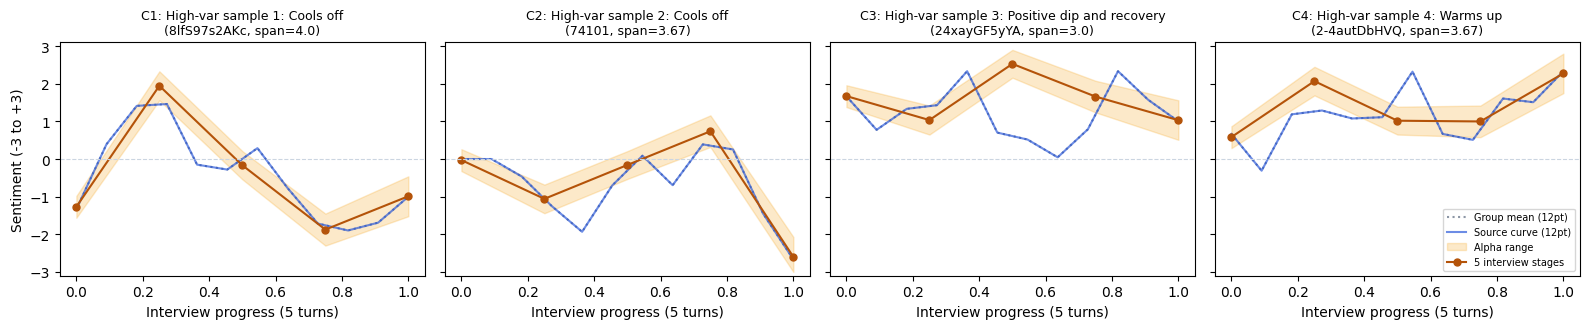

In [5]:
# Plot the 5-stage sentiment & emotion trajectories for the active SELECTION_METHOD
active_journeys = journeys_by_method[SELECTION_METHOD]
fig, axes = plt.subplots(1, len(active_journeys), figsize=(4.0 * len(active_journeys), 3.4), sharey=True)
if len(active_journeys) == 1:
    axes = [axes]
grid12 = np.linspace(0, 1, 12)
grid5 = np.linspace(0, 1, 5)
for ax, j in zip(axes, active_journeys):
    ax.plot(grid12, j.group_mean_12, ":", color="#8c96a5", label="Group mean (12pt)")
    ax.plot(grid12, j.curve_12, "-", color="#1d4ed8", alpha=0.65, label="Source curve (12pt)")
    stage_s = [s.sentiment for s in j.stages]
    stage_lo = [s.sentiment_range[0] for s in j.stages]
    stage_hi = [s.sentiment_range[1] for s in j.stages]
    ax.fill_between(grid5, stage_lo, stage_hi, color="#f59e0b", alpha=0.22, label="Alpha range")
    ax.plot(grid5, stage_s, "o-", color="#b45309", markersize=5, label="5 interview stages")
    ax.axhline(0, color="#cbd5e1", lw=0.8, ls="--")
    ax.set_title(f"{j.condition}: {j.label}\n({j.video_id}, span={j.sentiment_span})", fontsize=9)
    ax.set_xlabel("Interview progress (5 turns)")
    ax.set_ylim(-3.1, 3.1)
axes[0].set_ylabel("Sentiment (-3 to +3)")
axes[-1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

## 4. Load Persona & 5 Subscription Manager Interview Questions

Matches the exact persona (`Filomena Nguyen`) and the 5 Subscription Manager questions from `Dataset/Questions/Interview questions.txt` so outputs integrate directly with the rest of the team's notebooks.


In [6]:
personas_df = pd.read_csv(PERSONA_CSV, dtype=str, keep_default_na=False)
persona_row = personas_df.loc[personas_df["uuid"] == "0ee14f548c2c48c99b6ed3d8369e194b"].iloc[0]

PERSONA_TEXT = (
    f"Persona summary: {persona_row['persona'].strip()}\n"
    f"Professional background: {persona_row['professional_persona'].strip()}\n"
    f"Demographics: age {persona_row['age']}, {persona_row['sex']}, "
    f"{persona_row['occupation'].replace('_', ' ')}, {persona_row['city']}, {persona_row['state']}."
)

SHARED_INSTRUCTION = (
    "Review Subscription Manager from the perspective of your assigned persona. "
    "Explain your choices using specific details from the screens or feature description where relevant. "
    "If information you need is not shown, say what you would need to know rather than assume it. "
    "There is no preferred choice, and you do not need to suggest a change if none is needed."
)

QUESTIONS = [
    "[Screen 1: 01-details.jpg — Recurring Netflix charge of $22.99/month] How useful is this screen for deciding what to do about the Netflix charge? Which information would you rely on, and what, if anything, is missing or unclear?",
    "[Screen 2: 02-management.jpg — Options: Cancel subscription, Pause, or Set billing alert] Which option would you choose for Netflix at this point, and why? What, if anything, would you change about the available options or the information provided to support your decision?",
    "[Screen 3: 03-authorization.jpg — Authorization details before submitting cancellation] This screen is shown for review; seeing it does not mean you have chosen cancellation. Would you submit this request, go back, or seek more information, and why? What, if anything, would you need clarified about the request or the information being shared before deciding?",
    "[Screen 4: 04-submitted.jpg — Example request submitted, pending provider confirmation] For the next two screens, review a separate example in which a cancellation request was submitted. What do you understand the current status of the request to be, and what would you do next? What, if anything, should the product explain or offer differently at this stage?",
    "[Screen 5: 05-confirmed.jpg — Cancellation confirmed by provider] Continue reviewing the same example request. What does this screen tell you about the outcome and any remaining steps? Looking across the feature, would you use it to manage a relevant subscription, and why? What is the single most useful change you would make, if any?",
]

print(PERSONA_TEXT)
print("\nQuestions loaded:", len(QUESTIONS))

Persona summary: Filomena Nguyen navigates life with data‑driven curiosity and a flexible planning style that sometimes spirals into last‑minute scrambles, counterbalanced by regular yoga, a love for spontaneous hikes, and a habit of worrying about both work and personal projects.
Professional background: Filomena Nguyen, a 30‑year‑old operations manager, blends a practical, data‑driven mindset with an inquisitive curiosity to fine‑tune resource allocation, staff scheduling, and supply‑chain coordination, while their relaxed attitude toward strict timelines sometimes leads to disorganized to‑do lists that they compensate for by assertively negotiating with vendors and coaching front‑line employees in collaborative problem‑solving.
Demographics: age 30, Female, general or operations manager, Parsons, WV.

Questions loaded: 5


## 5. Preview Journey Design Prompts Across Parameter Combinations

Below we inspect how the exact same selected journey (`C1`) is formatted under different combinations of:
- `placement`: `"system_whole_journey"` (Persona + full 5-turn emotion cycle in system prompt, questions separate) vs. `"per_question_stage"` (per-turn emotion cue injected at each question).
- `granularity`: `"sentiment_only"` vs. `"emotion_breakdown"` (with all 6 discrete emotions + sarcastic/critical cues).
- `representation`: `"verbal"` vs. `"quant"`.
- `stochasticity`: `"fixed"` vs. `"range_or_alpha"`.


In [7]:
sample_journey = active_journeys[0]

for placement_mode in ["system_whole_journey", "per_question_stage"]:
    sys_prompt, turn_prompts, stage_cues = build_interview_prompts(
        persona_text=PERSONA_TEXT,
        shared_instruction=SHARED_INSTRUCTION,
        questions=QUESTIONS,
        journey=sample_journey,
        granularity=GRANULARITY,
        representation=REPRESENTATION,
        stochasticity=STOCHASTICITY,
        placement=placement_mode,
    )
    print("=" * 95)
    print(f"PLACEMENT = {placement_mode} | GRANULARITY = {GRANULARITY} | REPR = {REPRESENTATION} | STOCH = {STOCHASTICITY}")
    print("=" * 95)
    print("--- SYSTEM PROMPT ---")
    print(sys_prompt)
    print("\n--- TURN 1 USER PROMPT ---")
    print(turn_prompts[0])
    print("\n--- TURN 3 USER PROMPT ---")
    print(turn_prompts[2])
    print()

PLACEMENT = system_whole_journey | GRANULARITY = emotion_breakdown | REPR = quant | STOCH = range_or_alpha
--- SYSTEM PROMPT ---
You are participating in a product research interview as the following persona. Stay in first person, remain true to your background, and connect your answers naturally across the conversation using memory of your earlier responses.

### Persona Identity
Persona summary: Filomena Nguyen navigates life with data‑driven curiosity and a flexible planning style that sometimes spirals into last‑minute scrambles, counterbalanced by regular yoga, a love for spontaneous hikes, and a habit of worrying about both work and personal projects.
Professional background: Filomena Nguyen, a 30‑year‑old operations manager, blends a practical, data‑driven mindset with an inquisitive curiosity to fine‑tune resource allocation, staff scheduling, and supply‑chain coordination, while their relaxed attitude toward strict timelines sometimes leads to disorganized to‑do lists that the

## 6. Multi-Turn Interview Runner (with Conversation Memory & Optional 2-Step Chain)

Paste your Azure OpenAI credentials below to execute live multi-turn interviews across the design combinations in `EXPERIMENT_CONFIGS`. When credentials are left blank, the runner builds and saves the complete prompt and stage-cue tables without making network calls.


In [8]:
endpoint = ""
model_name = "gpt-4o"
deployment = "gpt-4o"
subscription_key = ""
api_version = "2024-12-01-preview"

# Define the combinations of Journey Selection + Journey Design levers to test
EXPERIMENT_CONFIGS = [
    {
        "config_id": "D0_baseline_memory",
        "selection_method": SELECTION_METHOD,
        "condition": "C0",
        "granularity": "sentiment_only",
        "representation": "verbal",
        "stochasticity": "fixed",
        "placement": "per_question_stage",
        "prompt_mode": "single_call",
    },
    {
        "config_id": "D1_whole_journey_system_verbal_emotions",
        "selection_method": SELECTION_METHOD,
        "condition": "C4",
        "granularity": "emotion_breakdown",
        "representation": "verbal",
        "stochasticity": "fixed",
        "placement": "system_whole_journey",
        "prompt_mode": "single_call",
    },
    {
        "config_id": "D2_per_turn_quant_fixed_emotions",
        "selection_method": SELECTION_METHOD,
        "condition": "C4",
        "granularity": "emotion_breakdown",
        "representation": "quant",
        "stochasticity": "fixed",
        "placement": "per_question_stage",
        "prompt_mode": "single_call",
    },
    {
        "config_id": "D3_per_turn_quant_range_two_step_chain",
        "selection_method": SELECTION_METHOD,
        "condition": "C4",
        "granularity": "emotion_breakdown",
        "representation": "quant",
        "stochasticity": "range_or_alpha",
        "placement": "per_question_stage",
        "prompt_mode": "two_step_chain",
    },
    {
        "config_id": "D4_random_high_var_two_step_chain",
        "selection_method": "random_high_var",
        "condition": "C1",
        "granularity": "emotion_breakdown",
        "representation": "quant",
        "stochasticity": "range_or_alpha",
        "placement": "per_question_stage",
        "prompt_mode": "two_step_chain",
    },
]

def azure_ready():
    return [
        name for name, val in [
            ("endpoint", endpoint),
            ("deployment", deployment),
            ("subscription_key", subscription_key),
            ("api_version", api_version),
        ] if not str(val).strip()
    ]

def call_azure_chat(messages, temperature=0.7):
    base = endpoint.rstrip("/")
    url = f"{base}/openai/deployments/{deployment}/chat/completions?api-version={api_version}"
    payload = {"messages": messages, "temperature": temperature}
    if model_name.strip():
        payload["model"] = model_name.strip()
    req = urllib.request.Request(
        url,
        data=json.dumps(payload).encode("utf-8"),
        headers={"api-key": subscription_key, "Content-Type": "application/json"},
        method="POST",
    )
    with urllib.request.urlopen(req, timeout=90) as resp:
        body = json.loads(resp.read().decode("utf-8"))
    return body["choices"][0]["message"]["content"].strip()

def run_multi_turn_interview(cfg):
    sel_method = cfg["selection_method"]
    cond = cfg["condition"]
    journey_obj = None
    if cond != "C0":
        method_list = journeys_by_method[sel_method]
        journey_obj = next(j for j in method_list if j.condition == cond)

    # For two_step_chain, Step A uses clean questions without per-turn cue squeezing,
    # then Step B applies the stage cue to modulate emotional delivery.
    effective_placement = "system_whole_journey" if cfg["placement"] == "system_whole_journey" else "per_question_stage"
    sys_prompt, user_turn_prompts, stage_cues = build_interview_prompts(
        persona_text=PERSONA_TEXT,
        shared_instruction=SHARED_INSTRUCTION,
        questions=QUESTIONS,
        journey=journey_obj,
        granularity=cfg["granularity"],
        representation=cfg["representation"],
        stochasticity=cfg["stochasticity"],
        placement=effective_placement,
    )

    missing_creds = azure_ready()
    history = [{"role": "system", "content": sys_prompt}]
    records = []

    for turn_idx, (question_text, turn_prompt, cue_text) in enumerate(zip(QUESTIONS, user_turn_prompts, stage_cues), 1):
        step_a_draft = ""
        final_answer = ""
        error_msg = ""

        if not missing_creds:
            try:
                if cfg["prompt_mode"] == "two_step_chain" and journey_obj is not None:
                    # Step A: substantive response from persona + conversation memory
                    step_a_user = f"Question {turn_idx} (Turn {turn_idx} of {len(QUESTIONS)}): {question_text}"
                    step_a_msgs = history + [{"role": "user", "content": step_a_user}]
                    step_a_draft = call_azure_chat(step_a_msgs, temperature=0.7)
                    # Step B: emotional modulation using the current stage cue
                    mod_prompt = build_two_step_modulation_prompt(
                        persona_text=PERSONA_TEXT,
                        question=question_text,
                        draft_answer=step_a_draft,
                        stage_cue=cue_text,
                    )
                    final_answer = call_azure_chat([{"role": "user", "content": mod_prompt}], temperature=0.7)
                    history.append({"role": "user", "content": step_a_user})
                    history.append({"role": "assistant", "content": final_answer})
                else:
                    # Single-call multi-turn with memory
                    history.append({"role": "user", "content": turn_prompt})
                    final_answer = call_azure_chat(history, temperature=0.7)
                    history.append({"role": "assistant", "content": final_answer})
            except Exception as exc:
                error_msg = f"{type(exc).__name__}: {exc}"
        else:
            # Record simulated conversation structure when previewing without API credentials
            history.append({"role": "user", "content": turn_prompt})
            history.append({"role": "assistant", "content": f"<pending_turn_{turn_idx}_response>"})

        st = journey_obj.stages[turn_idx - 1] if journey_obj is not None else None
        records.append({
            "config_id": cfg["config_id"],
            "selection_method": sel_method,
            "condition": cond,
            "video_id": journey_obj.video_id if journey_obj else "none",
            "journey_label": journey_obj.label if journey_obj else "Baseline (no journey)",
            "granularity": cfg["granularity"],
            "representation": cfg["representation"],
            "stochasticity": cfg["stochasticity"],
            "placement": cfg["placement"],
            "prompt_mode": cfg["prompt_mode"],
            "turn": turn_idx,
            "sentiment_target": st.sentiment if st else None,
            "sentiment_range": f"[{st.sentiment_range[0]:+.2f}, {st.sentiment_range[1]:+.2f}]" if st else "",
            "dominant_emotions": ", ".join(f"{e}:{v:.2f}" for e, v in st.dominant_emotions) if st else "",
            "stage_cue": cue_text,
            "system_prompt": sys_prompt if turn_idx == 1 else "(in conversation memory)",
            "user_turn_prompt": turn_prompt,
            "step_a_draft": step_a_draft,
            "final_answer": final_answer,
            "error": error_msg,
        })
    return records

all_records = []
for cfg in EXPERIMENT_CONFIGS:
    all_records.extend(run_multi_turn_interview(cfg))

responses_df = pd.DataFrame(all_records)
missing_creds = azure_ready()
if missing_creds:
    print("Preview mode (blank Azure credentials):", ", ".join(missing_creds))
    print(f"Prepared {len(responses_df)} multi-turn prompt records across {len(EXPERIMENT_CONFIGS)} configurations.")
else:
    filled = int(responses_df["final_answer"].astype(str).str.len().gt(0).sum())
    print(f"Generated {filled}/{len(responses_df)} answers across {len(EXPERIMENT_CONFIGS)} configurations.")

Generated 25/25 answers across 5 configurations.


## 7. Export Standardized Tables for Team Integration

Writes three tables to `OUTPUT_DIR`:
- `selected_journeys_v2.csv`: All selected journeys across all 4 selection methods (`provisional_4`, `cluster_k4`, `cluster_high_var`, `random_high_var`).
- `journey_stage_cues_v2.csv`: Turn-by-turn 7D affect targets, ranges, and formatted cues for every selected journey.
- `experiment_responses_v2.csv`: Full multi-turn prompts, intermediate Step A drafts (when `two_step_chain` is used), and final answers.


In [9]:
stage_cue_rows = []
for method, j_list in journeys_by_method.items():
    for j in j_list:
        for st in j.stages:
            stage_cue_rows.append({
                "selection_method": method,
                "condition": j.condition,
                "journey_label": j.label,
                "video_id": j.video_id,
                "source_cluster": j.source_cluster,
                "stage": st.stage,
                "relative_time": st.relative_time,
                "sentiment_cue": st.sentiment,
                "sentiment_delta": st.sentiment_delta,
                "sentiment_low": st.sentiment_range[0],
                "sentiment_high": st.sentiment_range[1],
                **{f"emo_{e}": st.emotions[e] for e in EMOTION_COLUMNS},
                "verbal_cue_emotions": format_stage_cue(st, "emotion_breakdown", "verbal", "fixed"),
                "quant_fixed_cue_emotions": format_stage_cue(st, "emotion_breakdown", "quant", "fixed"),
                "quant_range_cue_emotions": format_stage_cue(st, "emotion_breakdown", "quant", "range_or_alpha"),
            })

stage_cues_df = pd.DataFrame(stage_cue_rows)

journeys_path = os.path.join(OUTPUT_DIR, "selected_journeys_v2.csv")
cues_path = os.path.join(OUTPUT_DIR, "journey_stage_cues_v2.csv")
responses_path = os.path.join(OUTPUT_DIR, "experiment_responses_v2.csv")

comparison_df.to_csv(journeys_path, index=False)
stage_cues_df.to_csv(cues_path, index=False)
responses_df.to_csv(responses_path, index=False)

print("Saved:", journeys_path)
print("Saved:", cues_path)
print("Saved:", responses_path)
display(stage_cues_df.head(10))

Saved: /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/journey_design_outputs/selected_journeys_v2.csv
Saved: /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/journey_design_outputs/journey_stage_cues_v2.csv
Saved: /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/journey_design_outputs/experiment_responses_v2.csv


,selection_method,condition,journey_label,video_id,source_cluster,stage,relative_time,sentiment_cue,sentiment_delta,sentiment_low,sentiment_high,emo_happy,emo_sad,emo_anger,emo_surprise,emo_disgust,emo_fear,verbal_cue_emotions,quant_fixed_cue_emotions,quant_range_cue_emotions
0,provisional_4,C1,Warms up,etPDgRjrnJ8,0,1,0.00,0.000,0.000,-0.36,0.36,0.333,0.0,0.000,0.667,0.0,0.000,Private stage 1 behavioral guidance: Express a...,Private stage 1 behavioral guidance: Current s...,Private stage 1 behavioral guidance: Target se...
1,provisional_4,C1,Warms up,etPDgRjrnJ8,0,2,0.25,0.000,0.000,-0.36,0.36,0.108,0.0,0.000,0.216,0.0,0.000,Private stage 2 behavioral guidance: Express a...,Private stage 2 behavioral guidance: Current s...,Private stage 2 behavioral guidance: Target se...
2,provisional_4,C1,Warms up,etPDgRjrnJ8,0,3,0.50,0.461,0.461,0.14,0.78,0.154,0.0,0.000,0.000,0.0,0.000,Private stage 3 behavioral guidance: Express a...,Private stage 3 behavioral guidance: Current s...,Private stage 3 behavioral guidance: Target se...
3,provisional_4,C1,Warms up,etPDgRjrnJ8,0,4,0.75,1.000,0.539,0.70,1.30,0.333,0.0,0.000,0.000,0.0,0.000,Private stage 4 behavioral guidance: Express a...,Private stage 4 behavioral guidance: Current s...,Private stage 4 behavioral guidance: Target se...
4,provisional_4,C1,Warms up,etPDgRjrnJ8,0,5,1.00,1.000,0.000,0.66,1.34,0.333,0.0,0.000,0.000,0.0,0.000,Private stage 5 behavioral guidance: Express a...,Private stage 5 behavioral guidance: Current s...,Private stage 5 behavioral guidance: Target se...
5,provisional_4,C2,Positive dip and recovery,TXiOSZdaLJ8,4,1,0.00,0.667,0.000,0.39,0.95,0.333,0.0,0.000,0.000,0.0,0.000,Private stage 1 behavioral guidance: Express a...,Private stage 1 behavioral guidance: Current s...,Private stage 1 behavioral guidance: Target se...
6,provisional_4,C2,Positive dip and recovery,TXiOSZdaLJ8,4,2,0.25,0.311,-0.356,-0.02,0.64,0.155,0.0,0.356,0.000,0.0,0.178,Private stage 2 behavioral guidance: Express a...,Private stage 2 behavioral guidance: Current s...,Private stage 2 behavioral guidance: Target se...
7,provisional_4,C2,Positive dip and recovery,TXiOSZdaLJ8,4,3,0.50,0.020,-0.291,-0.30,0.34,0.000,0.0,0.647,0.000,0.0,0.313,Private stage 3 behavioral guidance: Express a...,Private stage 3 behavioral guidance: Current s...,Private stage 3 behavioral guidance: Target se...
8,provisional_4,C2,Positive dip and recovery,TXiOSZdaLJ8,4,4,0.75,0.177,0.157,-0.17,0.52,0.000,0.0,0.490,0.000,0.0,0.157,Private stage 4 behavioral guidance: Express a...,Private stage 4 behavioral guidance: Current s...,Private stage 4 behavioral guidance: Target se...
9,provisional_4,C2,Positive dip and recovery,TXiOSZdaLJ8,4,5,1.00,0.333,0.157,-0.08,0.75,0.000,0.0,0.333,0.000,0.0,0.000,Private stage 5 behavioral guidance: Express a...,Private stage 5 behavioral guidance: Current s...,Private stage 5 behavioral guidance: Target se...
